# Homework 4: Function Approximation and Monte Carlo Methods
**Student Name:** Kazi Habib Ullah  
**Course:** Computational Statistics  
 

---

## Question 1: Basis choice and approximation error


In [34]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import legvander
from scipy.interpolate import BSpline

# Setup data generation
rng = np.random.default_rng(2026)
n = 120
x = np.sort(rng.uniform(0, 1, n))

def f_true(x):
    return np.sin(2 * np.pi * x) + 0.65 * np.exp(-160 * (x - 0.72)**2)

y = f_true(x) + 0.25 * rng.normal(size=n)
x_grid = np.linspace(0, 1, 500)

# Define basis functions
def polynomial_basis(x, J):
    # Rescale x from [0, 1] to [-1, 1] for Legendre polynomials
    return legvander(2 * np.asarray(x) - 1, J - 1)

def fourier_basis(x, J):
    x = np.asarray(x)
    m = (J - 1) // 2
    columns = [np.ones_like(x)]
    for k in range(1, m + 1):
        columns.extend([np.cos(2 * np.pi * k * x), np.sin(2 * np.pi * k * x)])
    return np.column_stack(columns)

def bspline_basis(x, J, degree=3):
    K = J - degree - 1
    interior = np.linspace(0, 1, K + 2)[1:-1]
    knots = np.r_[np.repeat(0.0, degree + 1), interior, np.repeat(1.0, degree + 1)]
    return BSpline.design_matrix(x, knots, degree).toarray()



In [35]:
# Part 1: J = 11 design matrices and condition numbers
J_val = 11
Phi_poly = polynomial_basis(x, J_val)
Phi_four = fourier_basis(x, J_val)
Phi_bspl = bspline_basis(x, J_val)

def cond_num(Phi):
    s = np.linalg.svd(Phi, compute_uv=False)
    return s[0] / s[-1]

print("--- Part 1 Results (J = 11) ---")
print(f"Legendre Polynomial Basis - Shape: {Phi_poly.shape}, Condition Number: {cond_num(Phi_poly):.3f}")
print(f"Fourier Basis             - Shape: {Phi_four.shape}, Condition Number: {cond_num(Phi_four):.3f}")
print(f"Cubic B-Spline Basis      - Shape: {Phi_bspl.shape}, Condition Number: {cond_num(Phi_bspl):.3f}")

--- Part 1 Results (J = 11) ---
Legendre Polynomial Basis - Shape: (120, 11), Condition Number: 6.211
Fourier Basis             - Shape: (120, 11), Condition Number: 1.934
Cubic B-Spline Basis      - Shape: (120, 11), Condition Number: 7.419


### Part 1: Explanation 

* **Rescale to $[-1, 1]:$** Legendre polynomials are natively orthogonal on the domain $[-1, 1]$. Rescaling the predictor $x \in [0, 1]$ to $2x - 1 \in [-1, 1]$ ensures proper orthogonal properties, preventing severe numerical instability and floating-point overflow during high-degree polynomial evaluations.


--- Part 2 Results (J = 11) ---
Legendre: Training RMSE = 0.263, Grid RMSE = 0.107
Fourier:  Training RMSE = 0.259, Grid RMSE = 0.091
B-Spline: Training RMSE = 0.258, Grid RMSE = 0.108


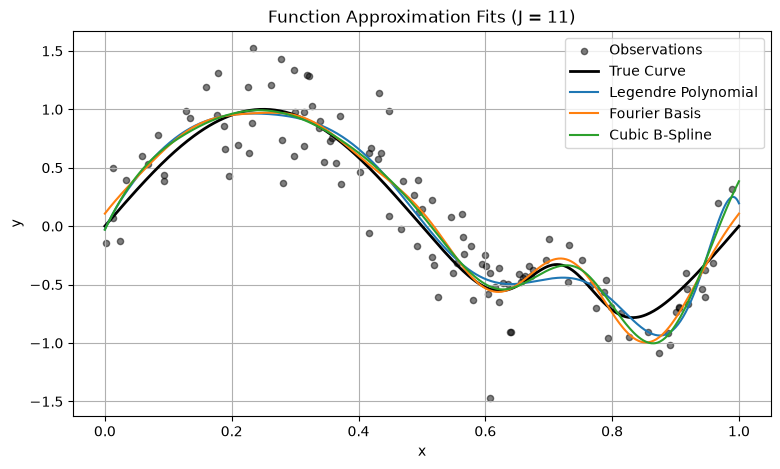

In [36]:
# Part 2: Least squares fit for J = 11 and plotting
def fit_and_evaluate(Phi_train, Phi_grid, y, f_true_grid):
    # Least squares coefficients: beta = (Phi^T Phi)^{-1} Phi^T y
    beta, _, _, _ = np.linalg.lstsq(Phi_train, y, rcond=None)
    y_pred_train = Phi_train @ beta
    y_pred_grid = Phi_grid @ beta
    
    train_rmse = np.sqrt(np.mean((y - y_pred_train)**2))
    grid_rmse = np.sqrt(np.mean((y_pred_grid - f_true_grid)**2))
    return beta, y_pred_grid, train_rmse, grid_rmse

f_true_grid = f_true(x_grid)

# Fit models
_, y_grid_poly, rmse_tr_poly, rmse_gr_poly = fit_and_evaluate(Phi_poly, polynomial_basis(x_grid, J_val), y, f_true_grid)
_, y_grid_four, rmse_tr_four, rmse_gr_four = fit_and_evaluate(Phi_four, fourier_basis(x_grid, J_val), y, f_true_grid)
_, y_grid_bspl, rmse_tr_bspl, rmse_gr_bspl = fit_and_evaluate(Phi_bspl, bspline_basis(x_grid, J_val), y, f_true_grid)

print("\n--- Part 2 Results (J = 11) ---")
print(f"Legendre: Training RMSE = {rmse_tr_poly:.3f}, Grid RMSE = {rmse_gr_poly:.3f}")
print(f"Fourier:  Training RMSE = {rmse_tr_four:.3f}, Grid RMSE = {rmse_gr_four:.3f}")
print(f"B-Spline: Training RMSE = {rmse_tr_bspl:.3f}, Grid RMSE = {rmse_gr_bspl:.3f}")

# Plotting fits
plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='black', alpha=0.5, s=20, label='Observations')
plt.plot(x_grid, f_true_grid, 'k-', linewidth=2, label='True Curve')
plt.plot(x_grid, y_grid_poly, label='Legendre Polynomial')
plt.plot(x_grid, y_grid_four, label='Fourier Basis')
plt.plot(x_grid, y_grid_bspl, label='Cubic B-Spline')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Function Approximation Fits (J = 11)')
plt.legend()
plt.grid(True)
plt.show()

### Question 1: Part 3 Table and Analysis ($J \in \{7, 11, 15\}$)

In [37]:
# Part 3: Repeat for J in {7, 11, 15}
J_values = [7, 11, 15]
results_table = []

for J in J_values:
    # Legendre
    _, _, tr_p, gr_p = fit_and_evaluate(polynomial_basis(x, J), polynomial_basis(x_grid, J), y, f_true_grid)
    # Fourier
    _, _, tr_f, gr_f = fit_and_evaluate(fourier_basis(x, J), fourier_basis(x_grid, J), y, f_true_grid)
    # B-Spline
    _, _, tr_b, gr_b = fit_and_evaluate(bspline_basis(x, J), bspline_basis(x_grid, J), y, f_true_grid)
    
    results_table.append((J, 'Legendre', tr_p, gr_p))
    results_table.append((J, 'Fourier', tr_f, gr_f))
    results_table.append((J, 'B-Spline', tr_b, gr_b))

print(f"{'J':<5} | {'Basis':<12} | {'Training RMSE':<15} | {'True-Curve Grid RMSE':<20}")
print("-" * 60)
for row in results_table:
    print(f"{row[0]:<5} | {row[1]:<12} | {row[2]:<15.4f} | {row[3]:<20.4f}")

J     | Basis        | Training RMSE   | True-Curve Grid RMSE
------------------------------------------------------------
7     | Legendre     | 0.2820          | 0.1155              
7     | Fourier      | 0.2717          | 0.0941              
7     | B-Spline     | 0.2807          | 0.1119              
11    | Legendre     | 0.2634          | 0.1069              
11    | Fourier      | 0.2592          | 0.0911              
11    | B-Spline     | 0.2584          | 0.1084              
15    | Legendre     | 0.2557          | 0.1148              
15    | Fourier      | 0.2528          | 0.1074              
15    | B-Spline     | 0.2572          | 0.1203              


### Question 1: Part 3 Interpretation
* **Training Error Behavior:** As $J$ increases, the training RMSE monotonically decreases (or stays flat) for all bases because adding more basis functions increases model flexibility, reducing approximation/bias error on the training sample.
* **True-Curve Grid Error Behavior:** Increasing $J$ can sometimes *increase* the true-curve grid error (overfitting). When $J$ becomes too large, the model begins to capture noise rather than the underlying signal, leading to high variance and erratic behavior between data points.

## Question 2: P-splines and selection of smoothness


In [38]:
# Question 2 Setup
J_q2 = 30
Phi_q2 = bspline_basis(x, J_q2)
Phi_grid_q2 = bspline_basis(x_grid, J_q2)
D2 = np.diff(np.eye(J_q2), n=2, axis=0)
Omega = D2.T @ D2



--- Part 1 Results ---
Selected Lambda: 2.00923e+00
Effective Degrees of Freedom (df): 11.718
Minimum GCV Value: 0.08029


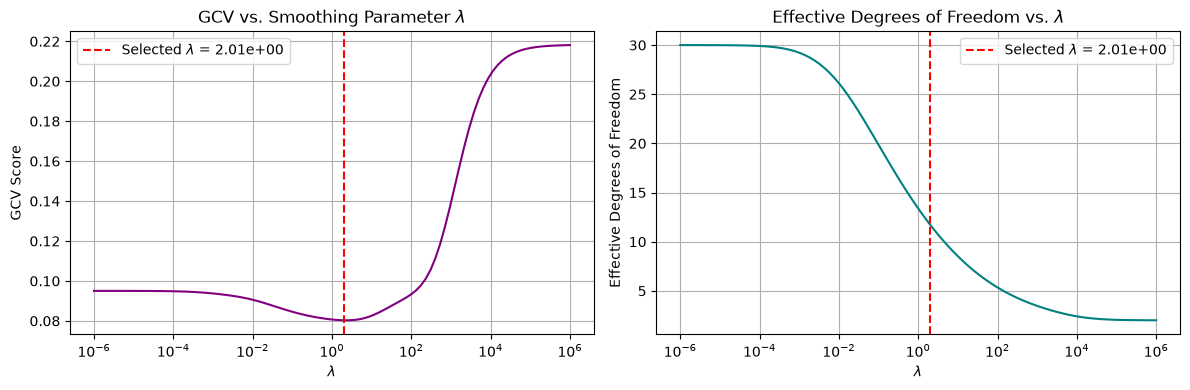

In [39]:
# Part 1: GCV across 100 lambda values from 10^-6 to 10^6
n_obs = len(y)
lambdas = np.logspace(-6, 6, 100)

gcv_scores = []
df_values = []

Phi_T_Phi = Phi_q2.T @ Phi_q2
Phi_T_y = Phi_q2.T @ y

for lam in lambdas:
    # Solve (Phi^T Phi + lambda Omega) beta = Phi^T y
    M = Phi_T_Phi + lam * Omega
    # Compute S_lambda diagonal trace via matrix inversion / solve
    # S_lambda = Phi @ inv(M) @ Phi^T
    # To find trace(S_lambda), note tr(A B) = tr(B A) -> tr(Phi^T Phi inv(M))
    inv_M = np.linalg.inv(M)
    df = np.trace(Phi_T_Phi @ inv_M)
    
    # Hat matrix projection y_hat = S_lambda @ y = Phi @ inv(M) @ Phi^T @ y
    beta_lam = inv_M @ Phi_T_y
    y_hat = Phi_q2 @ beta_lam
    
    residuals_norm_sq = np.sum((y - y_hat)**2)
    gcv = (residuals_norm_sq / n_obs) / ((1.0 - df / n_obs)**2)
    
    gcv_scores.append(gcv)
    df_values.append(df)

best_idx = np.argmin(gcv_scores)
best_lambda = lambdas[best_idx]
best_df = df_values[best_idx]
best_gcv = gcv_scores[best_idx]

print("--- Part 1 Results ---")
print(f"Selected Lambda: {best_lambda:.5e}")
print(f"Effective Degrees of Freedom (df): {best_df:.3f}")
print(f"Minimum GCV Value: {best_gcv:.5f}")

# Two-panel figure for GCV and df
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(lambdas, gcv_scores, color='purple')
ax1.axvline(best_lambda, color='red', linestyle='--', label=f'Selected $\\lambda$ = {best_lambda:.2e}')
ax1.set_xscale('log')
ax1.set_xlabel('$\\lambda$')
ax1.set_ylabel('GCV Score')
ax1.set_title('GCV vs. Smoothing Parameter $\\lambda$')
ax1.legend()
ax1.grid(True)

ax2.plot(lambdas, df_values, color='teal')
ax2.axvline(best_lambda, color='red', linestyle='--', label=f'Selected $\\lambda$ = {best_lambda:.2e}')
ax2.set_xscale('log')
ax2.set_xlabel('$\\lambda$')
ax2.set_ylabel('Effective Degrees of Freedom')
ax2.set_title('Effective Degrees of Freedom vs. $\\lambda$')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Model                               | Lambda          | Eff. DF    | Train RMSE   | Grid RMSE   
--------------------------------------------------------------------------------------------
Unpenalized (lambda = 0)            | 0.00e+00        | 30.00      | 0.2312       | 0.2350      
GCV-Selected (lambda = 2.01e+00)    | 2.01e+00        | 11.72      | 0.2557       | 0.0954      
Over-Smoothed (lambda = 10^6)       | 1.00e+06        | 2.01       | 0.4592       | 0.3791      


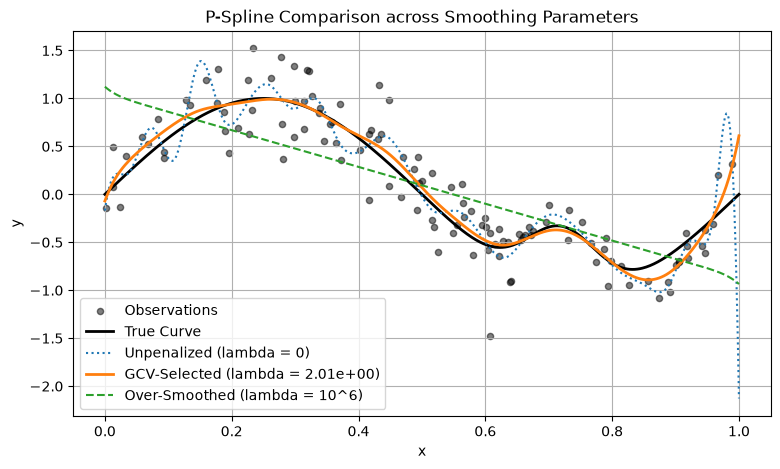

In [40]:
# Part 2: Compare unpenalized fit (lambda = 0), GCV-selected fit, and over-smoothed fit (lambda = 10^6)
# and generate a comparison table of metrics (Effective DF, Training RMSE, True-Curve Grid RMSE)[cite: 11].

lambdas_to_compare = [0.0, best_lambda, 1e6]
model_names = [
    "Unpenalized (lambda = 0)", 
    f"GCV-Selected (lambda = {best_lambda:.2e})", 
    "Over-Smoothed (lambda = 10^6)"
]

print(f"{'Model':<35} | {'Lambda':<15} | {'Eff. DF':<10} | {'Train RMSE':<12} | {'Grid RMSE':<12}")
print("-" * 92)

plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='black', alpha=0.5, s=20, label='Observations')
plt.plot(x_grid, f_true_grid, 'k-', linewidth=2, label='True Curve')

styles = [':', '-', '--']
linewidths = [1.5, 2.0, 1.5]

for lam, name, style, lw in zip(lambdas_to_compare, model_names, styles, linewidths):
    M = Phi_T_Phi + lam * Omega
    inv_M = np.linalg.inv(M)
    beta = inv_M @ Phi_T_y
    
    # Effective degrees of freedom: tr(S_lambda) = tr(Phi^T Phi (Phi^T Phi + lambda Omega)^{-1})
    df = np.trace(Phi_T_Phi @ inv_M)
    
    # Predictions
    y_pred_train = Phi_q2 @ beta
    y_pred_grid = Phi_grid_q2 @ beta
    
    # Error metrics
    train_rmse = np.sqrt(np.mean((y - y_pred_train)**2))
    grid_rmse = np.sqrt(np.mean((y_pred_grid - f_true_grid)**2))
    
    print(f"{name:<35} | {lam:<15.2e} | {df:<10.2f} | {train_rmse:<12.4f} | {grid_rmse:<12.4f}")
    
    plt.plot(x_grid, y_pred_grid, linestyle=style, linewidth=lw, label=name)

plt.xlabel('x')
plt.ylabel('y')
plt.title('P-Spline Comparison across Smoothing Parameters')
plt.legend()
plt.grid(True)
plt.show()

In [41]:
import sys
import numpy as np
import matplotlib
import scipy

print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version: {np.__version__}")
print(f"Matplotlib version: {matplotlib.__version__}")
print(f"SciPy version: {scipy.__version__}")

Python version: 3.14.7
NumPy version: 2.5.3
Matplotlib version: 3.11.1
SciPy version: 1.18.1
